# E-Commerce Inventory Health & Reorder Point Optimization

This project analyzes inventory across SKUs and warehouses, estimates stock coverage against supplier lead times, evaluates reorder status, forecasts daily demand for a sample SKU-warehouse combination, and creates replenishment recommendations.

**Tools:** Python, Pandas, Matplotlib, scikit-learn, MySQL, and Tableau.

**Business goal:** Use historical demand, current inventory, and supplier lead times to prioritize inventory reviews and reduce potential stockout risk.


In [ ]:
# Load the supply-chain dataset and preview its structure.
import pandas as pd

df = pd.read_csv("supply_chain_dataset1[1].csv")

df.head()

,Date,SKU_ID,Warehouse_ID,Supplier_ID,Region,Units_Sold,Inventory_Level,Supplier_Lead_Time_Days,Reorder_Point,Order_Quantity,Unit_Cost,Unit_Price,Promotion_Flag,Stockout_Flag,Demand_Forecast
0,2024-01-01,SKU_1,WH_1,SUP_8,West,10,592,14,379,0.0,13.95,20.48,0.0,0.0,8.52
1,2024-01-02,SKU_1,WH_1,SUP_8,West,17,575,14,379,0.0,13.95,20.48,0.0,0.0,18.63
2,2024-01-03,SKU_1,WH_1,SUP_8,North,35,540,14,379,0.0,13.95,20.48,1.0,0.0,39.62
3,2024-01-04,SKU_1,WH_1,SUP_8,South,24,516,14,379,0.0,13.95,20.48,0.0,0.0,19.43
4,2024-01-05,SKU_1,WH_1,SUP_8,West,21,495,14,379,0.0,13.95,20.48,0.0,0.0,18.70


In [ ]:
df.shape

(43897, 15)

In [ ]:
df.columns

Index(['Date', 'SKU_ID', 'Warehouse_ID', 'Supplier_ID', 'Region', 'Units_Sold',
       'Inventory_Level', 'Supplier_Lead_Time_Days', 'Reorder_Point',
       'Order_Quantity', 'Unit_Cost', 'Unit_Price', 'Promotion_Flag',
       'Stockout_Flag', 'Demand_Forecast'],
      dtype='object')

In [ ]:
df.dtypes

,0
Date,object
SKU_ID,object
Warehouse_ID,object
Supplier_ID,object
Region,object
Units_Sold,int64
Inventory_Level,int64
Supplier_Lead_Time_Days,int64
Reorder_Point,int64
Order_Quantity,float64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43897 entries, 0 to 43896
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Date                     43897 non-null  object 
 1   SKU_ID                   43897 non-null  object 
 2   Warehouse_ID             43897 non-null  object 
 3   Supplier_ID              43897 non-null  object 
 4   Region                   43897 non-null  object 
 5   Units_Sold               43897 non-null  int64  
 6   Inventory_Level          43897 non-null  int64  
 7   Supplier_Lead_Time_Days  43897 non-null  int64  
 8   Reorder_Point            43897 non-null  int64  
 9   Order_Quantity           43896 non-null  float64
 10  Unit_Cost                43896 non-null  float64
 11  Unit_Price               43896 non-null  float64
 12  Promotion_Flag           43896 non-null  float64
 13  Stockout_Flag            43896 non-null  float64
 14  Demand_Forecast       

In [ ]:
df.isnull().sum()

,0
Date,0
SKU_ID,0
Warehouse_ID,0
Supplier_ID,0
Region,0
Units_Sold,0
Inventory_Level,0
Supplier_Lead_Time_Days,0
Reorder_Point,0
Order_Quantity,1


In [ ]:
df.describe()

,Units_Sold,Inventory_Level,Supplier_Lead_Time_Days,Reorder_Point,Order_Quantity,Unit_Cost,Unit_Price,Promotion_Flag,Stockout_Flag,Demand_Forecast
count,43897.000000,43897.000000,43897.000000,43897.000000,43896.000000,43896.000000,43896.000000,43896.000000,43896.0,43896.000000
mean,20.077477,474.310568,8.143039,304.431396,19.272622,12.390864,18.588374,0.102766,0.0,20.102309
std,9.082221,131.741092,3.748594,52.261979,81.918505,4.494564,6.880216,0.303656,0.0,9.509134
min,0.000000,177.000000,2.000000,31.000000,0.000000,5.020000,7.170000,0.000000,0.0,0.000000
25%,13.000000,374.000000,5.000000,260.000000,0.000000,8.690000,12.470000,0.000000,0.0,12.940000
50%,20.000000,464.000000,8.000000,310.000000,0.000000,12.590000,18.560000,0.000000,0.0,19.940000
75%,27.000000,565.000000,11.000000,346.000000,0.000000,16.350000,23.340000,0.000000,0.0,26.940000
max,58.000000,981.000000,14.000000,396.000000,499.000000,19.760000,35.100000,1.000000,0.0,59.430000


In [ ]:
df[df.isnull().any(axis=1)]

,Date,SKU_ID,Warehouse_ID,Supplier_ID,Region,Units_Sold,Inventory_Level,Supplier_Lead_Time_Days,Reorder_Point,Order_Quantity,Unit_Cost,Unit_Price,Promotion_Flag,Stockout_Flag,Demand_Forecast
43896,2024-04-06,SKU_25,WH_1,SUP_10,East,27,468,5,31,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Remove rows containing missing values so subsequent calculations use complete records.
df = df.dropna()

In [ ]:
df.isnull().sum()

,0
Date,0
SKU_ID,0
Warehouse_ID,0
Supplier_ID,0
Region,0
Units_Sold,0
Inventory_Level,0
Supplier_Lead_Time_Days,0
Reorder_Point,0
Order_Quantity,0


In [ ]:
df.shape

(43896, 15)

In [ ]:
df['Date'] = pd.to_datetime(df['Date'])

In [ ]:
df.dtypes

,0
Date,datetime64[ns]
SKU_ID,object
Warehouse_ID,object
Supplier_ID,object
Region,object
Units_Sold,int64
Inventory_Level,int64
Supplier_Lead_Time_Days,int64
Reorder_Point,int64
Order_Quantity,float64


In [ ]:
df['Date'].min(), df['Date'].max()

(Timestamp('2024-01-01 00:00:00'), Timestamp('2024-12-30 00:00:00'))

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df[['Units_Sold',
    'Inventory_Level',
    'Supplier_Lead_Time_Days',
    'Reorder_Point',
    'Order_Quantity',
    'Unit_Cost',
    'Unit_Price',
    'Demand_Forecast']].min()

,0
Units_Sold,0.00
Inventory_Level,177.00
Supplier_Lead_Time_Days,2.00
Reorder_Point,207.00
Order_Quantity,0.00
Unit_Cost,5.02
Unit_Price,7.17
Demand_Forecast,0.00


In [ ]:
print("SKUs:", df['SKU_ID'].nunique())
print("Warehouses:", df['Warehouse_ID'].nunique())
print("Suppliers:", df['Supplier_ID'].nunique())
print("Regions:", df['Region'].unique())

SKUs: 25
Warehouses: 5
Suppliers: 10
Regions: ['West' 'North' 'South' 'East']


In [ ]:
df['Units_Sold'].describe()

,Units_Sold
count,43896.000000
mean,20.077319
std,9.082264
min,0.000000
25%,13.000000
50%,20.000000
75%,27.000000
max,58.000000


In [ ]:
# Summarize demand by SKU to compare total and typical sales across products.
sku_demand = (
    df.groupby('SKU_ID')['Units_Sold']
      .agg(['sum', 'mean', 'median', 'max'])
      .sort_values('sum', ascending=False)
)

sku_demand

,sum,mean,median,max
SKU_ID,,,,
SKU_18,37234,20.402192,20.0,52
SKU_1,37026,20.288219,20.0,52
SKU_13,36915,20.227397,20.0,54
SKU_9,36855,20.194521,20.0,46
SKU_4,36811,20.170411,20.0,50
SKU_12,36794,20.161096,20.0,54
SKU_3,36785,20.156164,20.0,55
SKU_20,36735,20.128767,20.0,53
SKU_8,36702,20.110685,20.0,48


In [ ]:
# Compare total and average demand across warehouses.
warehouse_demand = (
    df.groupby('Warehouse_ID')['Units_Sold']
      .agg(['sum', 'mean'])
      .sort_values('sum', ascending=False)
)

warehouse_demand

,sum,mean
Warehouse_ID,,
WH_1,178608,20.168022
WH_4,175963,20.087100
WH_5,175761,20.064041
WH_3,175541,20.038927
WH_2,175441,20.027511


In [ ]:
# Compare demand across regions to identify higher-volume areas.
region_demand = (
    df.groupby('Region')['Units_Sold']
      .agg(['sum', 'mean'])
      .sort_values('sum', ascending=False)
)

region_demand

,sum,mean
Region,,
North,222108,20.063957
South,221934,20.099076
West,219246,20.059103
East,218026,20.087157


In [ ]:
df.groupby('SKU_ID').size().sort_values()

,0
SKU_ID,
SKU_25,96
SKU_1,1825
SKU_11,1825
SKU_10,1825
SKU_13,1825
SKU_14,1825
SKU_15,1825
SKU_12,1825
SKU_17,1825


In [ ]:
df[df['SKU_ID'] == 'SKU_17']['Date'].min(), df[df['SKU_ID'] == 'SKU_17']['Date'].max()

(Timestamp('2024-01-01 00:00:00'), Timestamp('2024-12-30 00:00:00'))

In [ ]:
df[df['SKU_ID'] == 'SKU_17']['Warehouse_ID'].value_counts()

,count
Warehouse_ID,
WH_1,365
WH_2,365
WH_3,365
WH_4,365
WH_5,365


In [ ]:
# Compare average, minimum, and maximum inventory levels across warehouses.
warehouse_inventory = (
    df.groupby('Warehouse_ID')['Inventory_Level']
      .agg(['mean', 'min', 'max'])
      .sort_values('mean', ascending=False)
)

warehouse_inventory

,mean,min,max
Warehouse_ID,,,
WH_2,491.809361,183,974
WH_4,478.444178,194,953
WH_5,472.965753,198,980
WH_1,472.170732,196,971
WH_3,456.186986,177,981


In [ ]:
sku_warehouse_demand = (
    df.groupby(['SKU_ID', 'Warehouse_ID'])['Units_Sold']
      .agg(['sum', 'mean', 'median', 'max'])
      .reset_index()
)

sku_warehouse_demand.head(20)

,SKU_ID,Warehouse_ID,sum,mean,median,max
0,SKU_1,WH_1,7472,20.471233,21.0,50
1,SKU_1,WH_2,7299,19.997260,20.0,52
2,SKU_1,WH_3,7361,20.167123,20.0,46
3,SKU_1,WH_4,7449,20.408219,20.0,42
4,SKU_1,WH_5,7445,20.397260,21.0,49
5,SKU_10,WH_1,7307,20.019178,20.0,52
6,SKU_10,WH_2,7220,19.780822,20.0,53
7,SKU_10,WH_3,7279,19.942466,20.0,49
8,SKU_10,WH_4,7376,20.208219,21.0,47
9,SKU_10,WH_5,7397,20.265753,20.0,45


In [ ]:
sku_warehouse_inventory = (
    df.groupby(['SKU_ID', 'Warehouse_ID'])['Inventory_Level']
      .agg(['mean', 'min', 'max'])
      .reset_index()
)

sku_warehouse_inventory.head(20)

,SKU_ID,Warehouse_ID,mean,min,max
0,SKU_1,WH_1,555.547945,357,837
1,SKU_1,WH_2,492.498630,293,843
2,SKU_1,WH_3,483.684932,283,756
3,SKU_1,WH_4,494.764384,314,788
4,SKU_1,WH_5,546.912329,341,846
5,SKU_10,WH_1,527.383562,330,835
6,SKU_10,WH_2,470.391781,269,740
7,SKU_10,WH_3,385.254795,189,769
8,SKU_10,WH_4,504.126027,302,794
9,SKU_10,WH_5,408.734247,222,712


In [ ]:
sku_warehouse_analysis = sku_warehouse_demand.merge(
    sku_warehouse_inventory,
    on=['SKU_ID', 'Warehouse_ID']
)

sku_warehouse_analysis.head(20)

,SKU_ID,Warehouse_ID,sum,mean_x,median,max_x,mean_y,min,max_y
0,SKU_1,WH_1,7472,20.471233,21.0,50,555.547945,357,837
1,SKU_1,WH_2,7299,19.997260,20.0,52,492.498630,293,843
2,SKU_1,WH_3,7361,20.167123,20.0,46,483.684932,283,756
3,SKU_1,WH_4,7449,20.408219,20.0,42,494.764384,314,788
4,SKU_1,WH_5,7445,20.397260,21.0,49,546.912329,341,846
5,SKU_10,WH_1,7307,20.019178,20.0,52,527.383562,330,835
6,SKU_10,WH_2,7220,19.780822,20.0,53,470.391781,269,740
7,SKU_10,WH_3,7279,19.942466,20.0,49,385.254795,189,769
8,SKU_10,WH_4,7376,20.208219,21.0,47,504.126027,302,794
9,SKU_10,WH_5,7397,20.265753,20.0,45,408.734247,222,712


In [ ]:
# Estimate days of stock coverage as average inventory divided by average daily sales.
sku_warehouse_analysis['Stock_Coverage_Days'] = (
    sku_warehouse_analysis['mean_y'] /
    sku_warehouse_analysis['mean_x']
)

In [ ]:
sku_warehouse_analysis[
    ['SKU_ID', 'Warehouse_ID', 'mean_x', 'mean_y', 'Stock_Coverage_Days']
].head(20)

,SKU_ID,Warehouse_ID,mean_x,mean_y,Stock_Coverage_Days
0,SKU_1,WH_1,20.471233,555.547945,27.137982
1,SKU_1,WH_2,19.997260,492.498630,24.628305
2,SKU_1,WH_3,20.167123,483.684932,23.983834
3,SKU_1,WH_4,20.408219,494.764384,24.243388
4,SKU_1,WH_5,20.397260,546.912329,26.813029
5,SKU_10,WH_1,20.019178,527.383562,26.343917
6,SKU_10,WH_2,19.780822,470.391781,23.780194
7,SKU_10,WH_3,19.942466,385.254795,19.318313
8,SKU_10,WH_4,20.208219,504.126027,24.946584
9,SKU_10,WH_5,20.265753,408.734247,20.168717


In [ ]:

sku_warehouse_lead_time = (
    df.groupby(['SKU_ID', 'Warehouse_ID'])['Supplier_Lead_Time_Days']
      .mean()
      .reset_index()
)

sku_warehouse_analysis = sku_warehouse_analysis.merge(
    sku_warehouse_lead_time,
    on=['SKU_ID', 'Warehouse_ID']
)

sku_warehouse_analysis[
    [
        'SKU_ID',
        'Warehouse_ID',
        'mean_x',
        'mean_y',
        'Stock_Coverage_Days',
        'Supplier_Lead_Time_Days'
    ]
].head(20)


,SKU_ID,Warehouse_ID,mean_x,mean_y,Stock_Coverage_Days,Supplier_Lead_Time_Days
0,SKU_1,WH_1,20.471233,555.547945,27.137982,14.0
1,SKU_1,WH_2,19.997260,492.498630,24.628305,8.0
2,SKU_1,WH_3,20.167123,483.684932,23.983834,6.0
3,SKU_1,WH_4,20.408219,494.764384,24.243388,9.0
4,SKU_1,WH_5,20.397260,546.912329,26.813029,4.0
5,SKU_10,WH_1,20.019178,527.383562,26.343917,13.0
6,SKU_10,WH_2,19.780822,470.391781,23.780194,10.0
7,SKU_10,WH_3,19.942466,385.254795,19.318313,5.0
8,SKU_10,WH_4,20.208219,504.126027,24.946584,14.0
9,SKU_10,WH_5,20.265753,408.734247,20.168717,9.0


In [ ]:
# Flag a potential stockout when estimated stock coverage is shorter than supplier lead time.

sku_warehouse_analysis['Stock_Risk'] = (
    sku_warehouse_analysis.apply(
        lambda row: 'Stockout Risk'
        if row['Stock_Coverage_Days'] < row['Supplier_Lead_Time_Days']
        else 'Sufficient Coverage',
        axis=1
    )
)

sku_warehouse_analysis[
    [
        'SKU_ID',
        'Warehouse_ID',
        'Stock_Coverage_Days',
        'Supplier_Lead_Time_Days',
        'Stock_Risk'
    ]
].head(20)


,SKU_ID,Warehouse_ID,Stock_Coverage_Days,Supplier_Lead_Time_Days,Stock_Risk
0,SKU_1,WH_1,27.137982,14.0,Sufficient Coverage
1,SKU_1,WH_2,24.628305,8.0,Sufficient Coverage
2,SKU_1,WH_3,23.983834,6.0,Sufficient Coverage
3,SKU_1,WH_4,24.243388,9.0,Sufficient Coverage
4,SKU_1,WH_5,26.813029,4.0,Sufficient Coverage
5,SKU_10,WH_1,26.343917,13.0,Sufficient Coverage
6,SKU_10,WH_2,23.780194,10.0,Sufficient Coverage
7,SKU_10,WH_3,19.318313,5.0,Sufficient Coverage
8,SKU_10,WH_4,24.946584,14.0,Sufficient Coverage
9,SKU_10,WH_5,20.168717,9.0,Sufficient Coverage


In [ ]:

# Count SKU-warehouse combinations in each risk category
risk_summary = (
    sku_warehouse_analysis['Stock_Risk']
    .value_counts()
    .reset_index()
)

risk_summary.columns = ['Stock_Risk', 'Count']

risk_summary


,Stock_Risk,Count
0,Sufficient Coverage,121


In [ ]:

stockout_products = sku_warehouse_analysis[
    sku_warehouse_analysis['Stock_Risk'] == 'Stockout Risk'
]

stockout_products[
    [
        'SKU_ID',
        'Warehouse_ID',
        'Stock_Coverage_Days',
        'Supplier_Lead_Time_Days',
        'Stock_Risk'
    ]
]


,SKU_ID,Warehouse_ID,Stock_Coverage_Days,Supplier_Lead_Time_Days,Stock_Risk


In [ ]:

print("Total SKU-warehouse combinations:", len(sku_warehouse_analysis))

print("\nRisk category counts:")
print(sku_warehouse_analysis['Stock_Risk'].value_counts())

print("\nSmallest stock coverage:")
print(
    sku_warehouse_analysis[
        [
            'SKU_ID',
            'Warehouse_ID',
            'Stock_Coverage_Days',
            'Supplier_Lead_Time_Days'
        ]
    ].sort_values('Stock_Coverage_Days').head(10)
)


Total SKU-warehouse combinations: 121

Risk category counts:
Stock_Risk
Sufficient Coverage    121
Name: count, dtype: int64

Smallest stock coverage:
     SKU_ID Warehouse_ID  Stock_Coverage_Days  Supplier_Lead_Time_Days
85   SKU_25         WH_1            17.952031                      5.0
72   SKU_22         WH_3            18.401545                      4.0
113   SKU_8         WH_3            18.971712                      4.0
7    SKU_10         WH_3            19.318313                      5.0
102   SKU_6         WH_2            19.415854                     14.0
82   SKU_24         WH_3            19.544769                     10.0
47   SKU_18         WH_3            19.599918                      9.0
33   SKU_15         WH_4            19.871950                      5.0
75   SKU_23         WH_1            19.878775                      8.0
110   SKU_7         WH_5            20.012448                      8.0


In [ ]:

sku_warehouse_reorder = (
    df.groupby(['SKU_ID', 'Warehouse_ID'])['Reorder_Point']
      .mean()
      .reset_index()
)

sku_warehouse_analysis = sku_warehouse_analysis.merge(
    sku_warehouse_reorder,
    on=['SKU_ID', 'Warehouse_ID']
)

sku_warehouse_analysis[
    [
        'SKU_ID',
        'Warehouse_ID',
        'mean_y',
        'Reorder_Point'
    ]
].head(10)


,SKU_ID,Warehouse_ID,mean_y,Reorder_Point
0,SKU_1,WH_1,555.547945,379.0
1,SKU_1,WH_2,492.498630,322.0
2,SKU_1,WH_3,483.684932,314.0
3,SKU_1,WH_4,494.764384,333.0
4,SKU_1,WH_5,546.912329,366.0
5,SKU_10,WH_1,527.383562,361.0
6,SKU_10,WH_2,470.391781,310.0
7,SKU_10,WH_3,385.254795,218.0
8,SKU_10,WH_4,504.126027,328.0
9,SKU_10,WH_5,408.734247,246.0


In [ ]:
# Compare average inventory with the reorder point for each SKU-warehouse combination.

sku_warehouse_analysis['Reorder_Status'] = (
    sku_warehouse_analysis.apply(
        lambda row: 'Below Reorder Point'
        if row['mean_y'] < row['Reorder_Point']
        else 'At or Above Reorder Point',
        axis=1
    )
)

print(sku_warehouse_analysis['Reorder_Status'].value_counts())


Reorder_Status
At or Above Reorder Point    121
Name: count, dtype: int64


In [ ]:

sku_warehouse_analysis['Inventory_Above_Reorder'] = (
    sku_warehouse_analysis['mean_y']
    - sku_warehouse_analysis['Reorder_Point']
)

sku_warehouse_analysis[
    [
        'SKU_ID',
        'Warehouse_ID',
        'mean_y',
        'Reorder_Point',
        'Inventory_Above_Reorder'
    ]
].sort_values(
    'Inventory_Above_Reorder',
    ascending=False
).head(10)


,SKU_ID,Warehouse_ID,mean_y,Reorder_Point,Inventory_Above_Reorder
18,SKU_12,WH_4,428.284932,227.0,201.284932
10,SKU_11,WH_1,484.139726,286.0,198.139726
11,SKU_11,WH_2,426.797260,230.0,196.797260
20,SKU_13,WH_1,440.602740,246.0,194.602740
23,SKU_13,WH_4,443.854795,251.0,192.854795
91,SKU_4,WH_1,486.772603,298.0,188.772603
55,SKU_2,WH_1,416.515068,228.0,188.515068
59,SKU_2,WH_5,454.876712,267.0,187.876712
107,SKU_7,WH_2,582.219178,396.0,186.219178
57,SKU_2,WH_3,504.641096,319.0,185.641096


In [ ]:
# Estimate demand expected during supplier lead time using average daily sales.

sku_warehouse_analysis['Lead_Time_Demand'] = (
    sku_warehouse_analysis['mean_x']
    * sku_warehouse_analysis['Supplier_Lead_Time_Days']
)

sku_warehouse_analysis[
    [
        'SKU_ID',
        'Warehouse_ID',
        'mean_x',
        'Supplier_Lead_Time_Days',
        'Lead_Time_Demand',
        'Reorder_Point'
    ]
].head(10)


,SKU_ID,Warehouse_ID,mean_x,Supplier_Lead_Time_Days,Lead_Time_Demand,Reorder_Point
0,SKU_1,WH_1,20.471233,14.0,286.597260,379.0
1,SKU_1,WH_2,19.997260,8.0,159.978082,322.0
2,SKU_1,WH_3,20.167123,6.0,121.002740,314.0
3,SKU_1,WH_4,20.408219,9.0,183.673973,333.0
4,SKU_1,WH_5,20.397260,4.0,81.589041,366.0
5,SKU_10,WH_1,20.019178,13.0,260.249315,361.0
6,SKU_10,WH_2,19.780822,10.0,197.808219,310.0
7,SKU_10,WH_3,19.942466,5.0,99.712329,218.0
8,SKU_10,WH_4,20.208219,14.0,282.915068,328.0
9,SKU_10,WH_5,20.265753,9.0,182.391781,246.0


In [ ]:
# Measure the difference between the reorder point and estimated lead-time demand.

sku_warehouse_analysis['Reorder_Point_Buffer'] = (
    sku_warehouse_analysis['Reorder_Point']
    - sku_warehouse_analysis['Lead_Time_Demand']
)

sku_warehouse_analysis[
    [
        'SKU_ID',
        'Warehouse_ID',
        'Lead_Time_Demand',
        'Reorder_Point',
        'Reorder_Point_Buffer'
    ]
].sort_values(
    'Reorder_Point_Buffer'
).head(10)


,SKU_ID,Warehouse_ID,Lead_Time_Demand,Reorder_Point,Reorder_Point_Buffer
102,SKU_6,WH_2,279.194521,217.0,-62.194521
86,SKU_3,WH_1,282.071233,240.0,-42.071233
78,SKU_23,WH_4,277.161644,236.0,-41.161644
55,SKU_2,WH_1,260.356164,228.0,-32.356164
18,SKU_12,WH_4,244.734247,227.0,-17.734247
26,SKU_14,WH_2,284.334247,268.0,-16.334247
59,SKU_2,WH_5,280.460274,267.0,-13.460274
94,SKU_4,WH_4,241.019178,233.0,-8.019178
34,SKU_15,WH_5,281.265753,279.0,-2.265753
104,SKU_6,WH_4,218.884932,220.0,1.115068


In [ ]:

# Step 1: Identify daily records where inventory is below the reorder point
df['Below_Reorder_Point'] = (
    df['Inventory_Level'] < df['Reorder_Point']
)

# Step 2: Summarize the number of days below the reorder point
reorder_breach_analysis = (
    df.groupby(['SKU_ID', 'Warehouse_ID'])
      .agg(
          Total_Days=('Date', 'nunique'),
          Days_Below_Reorder=('Below_Reorder_Point', 'sum')
      )
      .reset_index()
)

# Step 3: Calculate the percentage of days below the reorder point
reorder_breach_analysis['Breach_Percentage'] = (
    reorder_breach_analysis['Days_Below_Reorder']
    / reorder_breach_analysis['Total_Days']
) * 100

# Step 4: Display the 10 combinations with the most breach days
reorder_breach_analysis = reorder_breach_analysis.sort_values(
    'Days_Below_Reorder', ascending=False
)

reorder_breach_analysis.head(10)


,SKU_ID,Warehouse_ID,Total_Days,Days_Below_Reorder,Breach_Percentage
26,SKU_14,WH_2,365,23,6.301370
49,SKU_18,WH_5,365,23,6.301370
114,SKU_8,WH_4,365,23,6.301370
54,SKU_19,WH_5,365,22,6.027397
44,SKU_17,WH_5,365,22,6.027397
74,SKU_22,WH_5,365,22,6.027397
109,SKU_7,WH_4,365,22,6.027397
60,SKU_20,WH_1,365,22,6.027397
16,SKU_12,WH_2,365,22,6.027397
29,SKU_14,WH_5,365,21,5.753425


In [ ]:

# Summarize recorded stockouts for each SKU and warehouse
stockout_analysis = (
    df.groupby(['SKU_ID', 'Warehouse_ID'])
      .agg(
          Total_Days=('Date', 'nunique'),
          Stockout_Days=('Stockout_Flag', 'sum'),
          Reorder_Breach_Days=('Below_Reorder_Point', 'sum')
      )
      .reset_index()
)

# Calculate the percentage of days with recorded stockouts
stockout_analysis['Stockout_Percentage'] = (
    stockout_analysis['Stockout_Days']
    / stockout_analysis['Total_Days']
) * 100

# Show combinations with the most recorded stockout days
stockout_analysis = stockout_analysis.sort_values(
    'Stockout_Days', ascending=False
)

stockout_analysis.head(10)


,SKU_ID,Warehouse_ID,Total_Days,Stockout_Days,Reorder_Breach_Days,Stockout_Percentage
0,SKU_1,WH_1,365,0.0,20,0.0
1,SKU_1,WH_2,365,0.0,17,0.0
2,SKU_1,WH_3,365,0.0,18,0.0
3,SKU_1,WH_4,365,0.0,18,0.0
4,SKU_1,WH_5,365,0.0,19,0.0
5,SKU_10,WH_1,365,0.0,20,0.0
6,SKU_10,WH_2,365,0.0,20,0.0
7,SKU_10,WH_3,365,0.0,20,0.0
8,SKU_10,WH_4,365,0.0,19,0.0
9,SKU_10,WH_5,365,0.0,21,0.0


In [ ]:

# Check the possible values and their frequencies
df['Stockout_Flag'].value_counts(dropna=False)


,count
Stockout_Flag,
0.0,43896


In [ ]:

print("Dataset shape:", df.shape)

print("\nStockout flag values:")
print(df['Stockout_Flag'].value_counts(dropna=False))

print("\nUnique stockout flag values:")
print(df['Stockout_Flag'].unique())


Dataset shape: (43896, 16)

Stockout flag values:
Stockout_Flag
0.0    43896
Name: count, dtype: int64

Unique stockout flag values:
[0.]


In [ ]:

print(df.columns.tolist())
print(df.head())
print(df['Date'].min(), "to", df['Date'].max())
print(df[['SKU_ID', 'Warehouse_ID']].drop_duplicates().shape)


['Date', 'SKU_ID', 'Warehouse_ID', 'Supplier_ID', 'Region', 'Units_Sold', 'Inventory_Level', 'Supplier_Lead_Time_Days', 'Reorder_Point', 'Order_Quantity', 'Unit_Cost', 'Unit_Price', 'Promotion_Flag', 'Stockout_Flag', 'Demand_Forecast', 'Below_Reorder_Point']
        Date SKU_ID Warehouse_ID Supplier_ID Region  Units_Sold  \
0 2024-01-01  SKU_1         WH_1       SUP_8   West          10   
1 2024-01-02  SKU_1         WH_1       SUP_8   West          17   
2 2024-01-03  SKU_1         WH_1       SUP_8  North          35   
3 2024-01-04  SKU_1         WH_1       SUP_8  South          24   
4 2024-01-05  SKU_1         WH_1       SUP_8   West          21   

   Inventory_Level  Supplier_Lead_Time_Days  Reorder_Point  Order_Quantity  \
0              592                       14            379             0.0   
1              575                       14            379             0.0   
2              540                       14            379             0.0   
3              516        

In [ ]:

print("Data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDemand summary:")
print(df['Units_Sold'].describe())


Data types:
Date                       datetime64[ns]
SKU_ID                             object
Warehouse_ID                       object
Supplier_ID                        object
Region                             object
Units_Sold                          int64
Inventory_Level                     int64
Supplier_Lead_Time_Days             int64
Reorder_Point                       int64
Order_Quantity                    float64
Unit_Cost                         float64
Unit_Price                        float64
Promotion_Flag                    float64
Stockout_Flag                     float64
Demand_Forecast                   float64
Below_Reorder_Point                  bool
dtype: object

Missing values:
Date                       0
SKU_ID                     0
Warehouse_ID               0
Supplier_ID                0
Region                     0
Units_Sold                 0
Inventory_Level            0
Supplier_Lead_Time_Days    0
Reorder_Point              0
Order_Quantity          

In [ ]:
# Select SKU_1 at WH_1 and calculate a trailing 7-day average to smooth daily sales fluctuations.

# Select one product in one warehouse
sample_demand = df[
    (df['SKU_ID'] == 'SKU_1') &
    (df['Warehouse_ID'] == 'WH_1')
].sort_values('Date')

# Calculate a 7-day rolling average of sales
sample_demand['7_Day_Avg_Demand'] = (
    sample_demand['Units_Sold']
    .rolling(window=7)
    .mean()
)

# Display the first 15 days
sample_demand[
    ['Date', 'Units_Sold', '7_Day_Avg_Demand']
].head(15)


,Date,Units_Sold,7_Day_Avg_Demand
0,2024-01-01,10,NaN
1,2024-01-02,17,NaN
2,2024-01-03,35,NaN
3,2024-01-04,24,NaN
4,2024-01-05,21,NaN
5,2024-01-06,18,NaN
6,2024-01-07,19,20.571429
7,2024-01-08,23,22.428571
8,2024-01-09,25,23.571429
9,2024-01-10,25,22.142857


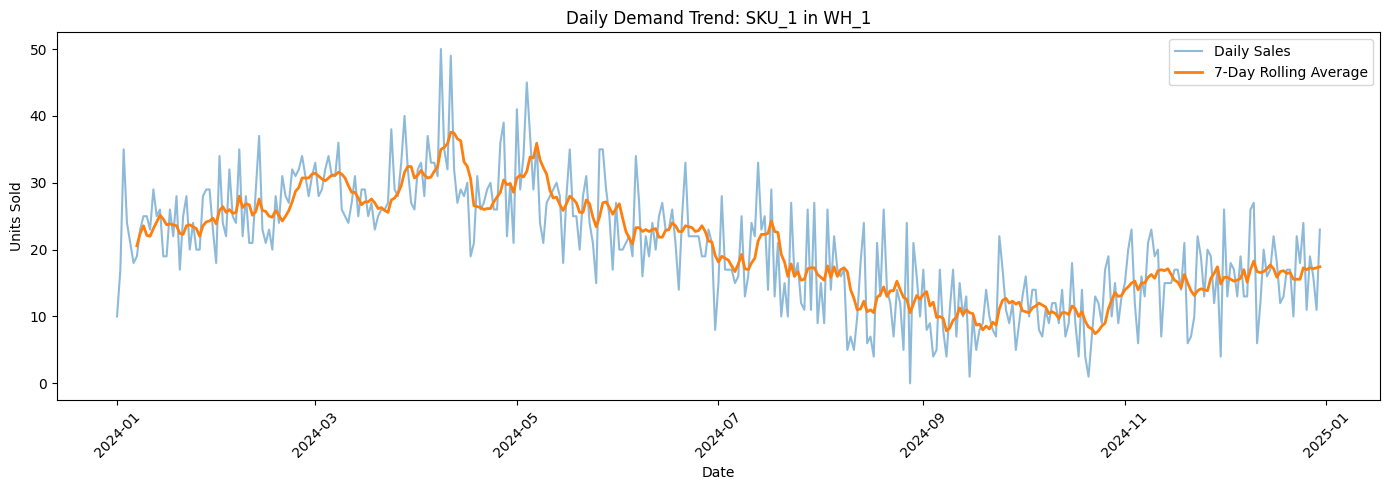

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    sample_demand['Date'],
    sample_demand['Units_Sold'],
    label='Daily Sales',
    alpha=0.5
)

plt.plot(
    sample_demand['Date'],
    sample_demand['7_Day_Avg_Demand'],
    label='7-Day Rolling Average',
    linewidth=2
)

plt.title('Daily Demand Trend: SKU_1 in WH_1')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
# Build forecasting features using only prior sales history plus promotion and calendar information.

# Start with the daily sales history for SKU_1 in WH_1
forecast_df = sample_demand[
    ['Date', 'Units_Sold', 'Promotion_Flag']
].copy()

# Previous day's sales
forecast_df['Previous_Day_Sales'] = (
    forecast_df['Units_Sold'].shift(1)
)

# Average sales over the previous 7 days
forecast_df['Previous_7_Day_Avg'] = (
    forecast_df['Units_Sold'].shift(1)
    .rolling(window=7)
    .mean()
)

# Month can help the model learn seasonal patterns
forecast_df['Month'] = forecast_df['Date'].dt.month

# Display the prepared features
forecast_df.head(12)


,Date,Units_Sold,Promotion_Flag,Previous_Day_Sales,Previous_7_Day_Avg,Month
0,2024-01-01,10,0.0,NaN,NaN,1
1,2024-01-02,17,0.0,10.0,NaN,1
2,2024-01-03,35,1.0,17.0,NaN,1
3,2024-01-04,24,0.0,35.0,NaN,1
4,2024-01-05,21,0.0,24.0,NaN,1
5,2024-01-06,18,0.0,21.0,NaN,1
6,2024-01-07,19,0.0,18.0,NaN,1
7,2024-01-08,23,1.0,19.0,20.571429,1
8,2024-01-09,25,0.0,23.0,22.428571,1
9,2024-01-10,25,0.0,25.0,23.571429,1


In [ ]:

print(forecast_df.columns.tolist())

print(
    forecast_df[
        [
            'Date',
            'Units_Sold',
            'Promotion_Flag',
            'Previous_Day_Sales',
            'Previous_7_Day_Avg',
            'Month'
        ]
    ].head(12).to_string(index=False)
)


['Date', 'Units_Sold', 'Promotion_Flag', 'Previous_Day_Sales', 'Previous_7_Day_Avg', 'Month']
      Date  Units_Sold  Promotion_Flag  Previous_Day_Sales  Previous_7_Day_Avg  Month
2024-01-01          10             0.0                 NaN                 NaN      1
2024-01-02          17             0.0                10.0                 NaN      1
2024-01-03          35             1.0                17.0                 NaN      1
2024-01-04          24             0.0                35.0                 NaN      1
2024-01-05          21             0.0                24.0                 NaN      1
2024-01-06          18             0.0                21.0                 NaN      1
2024-01-07          19             0.0                18.0                 NaN      1
2024-01-08          23             1.0                19.0           20.571429      1
2024-01-09          25             0.0                23.0           22.428571      1
2024-01-10          25             0.0        

In [ ]:
# Remove rows missing lagged features, then split chronologically to avoid training on future dates.

# Remove rows with missing historical features
forecast_df_clean = forecast_df.dropna().copy()

# Define the features used to make predictions
features = [
    'Promotion_Flag',
    'Previous_Day_Sales',
    'Previous_7_Day_Avg',
    'Month'
]

# Define the value we want to predict
target = 'Units_Sold'

# Train on January–September; test on October–December
train_df = forecast_df_clean[
    forecast_df_clean['Date'] < '2024-10-01'
]

test_df = forecast_df_clean[
    forecast_df_clean['Date'] >= '2024-10-01'
]

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", train_df['Date'].min(), "to", train_df['Date'].max())
print("Testing period:", test_df['Date'].min(), "to", test_df['Date'].max())


Training rows: 267
Testing rows: 91
Training period: 2024-01-08 00:00:00 to 2024-09-30 00:00:00
Testing period: 2024-10-01 00:00:00 to 2024-12-30 00:00:00


In [ ]:
# Train a Random Forest regressor and evaluate demand predictions on the held-out test period.

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create the model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train using January–September data
model.fit(X_train, y_train)

# Predict sales for October–December
y_pred = model.predict(X_test)

# Evaluate prediction errors
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))


Mean Absolute Error (MAE): 4.91
Root Mean Squared Error (RMSE): 6.1


In [ ]:
# Compare the machine-learning model against a simple previous-day-sales baseline.

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Baseline: predict today's sales using yesterday's sales
baseline_pred = X_test['Previous_Day_Sales'].to_numpy()

# Evaluate baseline performance
baseline_mae = mean_absolute_error(y_test, baseline_pred)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)

print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))

print("\nRandom Forest MAE:", round(mae, 2))
print("Random Forest RMSE:", round(rmse, 2))


Baseline MAE: 5.58
Baseline RMSE: 7.09

Random Forest MAE: 4.91
Random Forest RMSE: 6.1


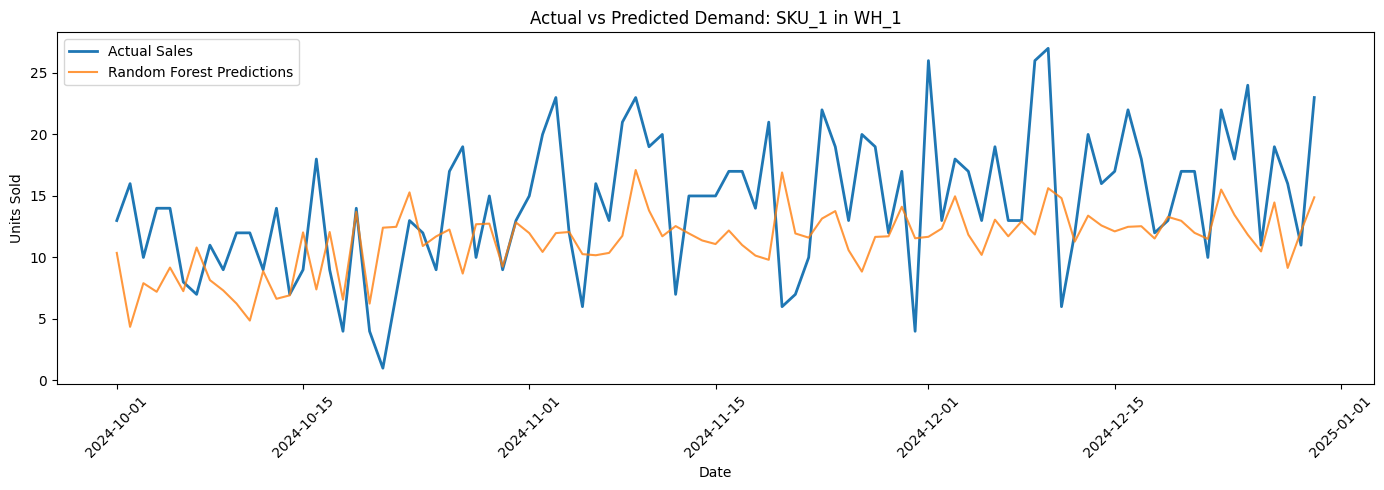

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    test_df['Date'],
    y_test.to_numpy(),
    label='Actual Sales',
    linewidth=2
)

plt.plot(
    test_df['Date'],
    y_pred,
    label='Random Forest Predictions',
    alpha=0.8
)

plt.title('Actual vs Predicted Demand: SKU_1 in WH_1')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd

feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    'Importance',
    ascending=False
)

print(feature_importance)


              Feature  Importance
2  Previous_7_Day_Avg    0.444839
3               Month    0.353069
1  Previous_Day_Sales    0.150446
0      Promotion_Flag    0.051646


In [ ]:
# Convert test predictions into a results table and estimate demand over the supplier lead time.

# Create a table of actual and predicted demand for the test period
forecast_results = pd.DataFrame({
    'Date': test_df['Date'].to_numpy(),
    'Actual_Sales': y_test.to_numpy(),
    'Predicted_Sales': y_pred
})

# Estimate average predicted daily demand in the test period
avg_predicted_demand = forecast_results['Predicted_Sales'].mean()

# Get the supplier lead time for SKU_1 in WH_1
lead_time = df[
    (df['SKU_ID'] == 'SKU_1') &
    (df['Warehouse_ID'] == 'WH_1')
]['Supplier_Lead_Time_Days'].iloc[0]

# Estimate demand during supplier lead time
predicted_lead_time_demand = avg_predicted_demand * lead_time

print("Average predicted daily demand:",
      round(avg_predicted_demand, 2))

print("Supplier lead time:", lead_time, "days")

print("Estimated lead-time demand:",
      round(predicted_lead_time_demand, 2), "units")


Average predicted daily demand: 11.34
Supplier lead time: 14 days
Estimated lead-time demand: 158.79 units


In [ ]:

# Get the reorder point for SKU_1 in WH_1
reorder_point = df[
    (df['SKU_ID'] == 'SKU_1') &
    (df['Warehouse_ID'] == 'WH_1')
]['Reorder_Point'].iloc[0]

# Compare the reorder point with predicted lead-time demand
buffer = reorder_point - predicted_lead_time_demand

print("Reorder Point:", reorder_point)
print("Predicted Lead-Time Demand:",
      round(predicted_lead_time_demand, 2))
print("Difference:", round(buffer, 2))


Reorder Point: 379
Predicted Lead-Time Demand: 158.79
Difference: 220.21


In [ ]:

# Inspect the latest records for SKU_1 in WH_1
sku1_wh1 = df[
    (df['SKU_ID'] == 'SKU_1') &
    (df['Warehouse_ID'] == 'WH_1')
].sort_values('Date')

print(
    sku1_wh1[
        [
            'Date',
            'Inventory_Level',
            'Order_Quantity',
            'Reorder_Point',
            'Supplier_Lead_Time_Days',
            'Units_Sold'
        ]
    ].tail(10).to_string(index=False)
)


      Date  Inventory_Level  Order_Quantity  Reorder_Point  Supplier_Lead_Time_Days  Units_Sold
2024-12-21              778             0.0            379                       14          17
2024-12-22              768             0.0            379                       14          10
2024-12-23              746             0.0            379                       14          22
2024-12-24              728             0.0            379                       14          18
2024-12-25              704             0.0            379                       14          24
2024-12-26              693             0.0            379                       14          11
2024-12-27              674             0.0            379                       14          19
2024-12-28              658             0.0            379                       14          16
2024-12-29              647             0.0            379                       14          11
2024-12-30              624             

In [ ]:
# Use each SKU-warehouse combination's latest dated record as its current inventory snapshot.

# Get the latest record for every SKU in every warehouse
latest_inventory = (
    df.sort_values('Date')
      .groupby(['SKU_ID', 'Warehouse_ID'])
      .tail(1)
      .copy()
      .reset_index(drop=True)
)

# Keep the columns needed for replenishment analysis
replenishment = latest_inventory[
    [
        'SKU_ID',
        'Warehouse_ID',
        'Date',
        'Inventory_Level',
        'Reorder_Point',
        'Supplier_Lead_Time_Days',
        'Order_Quantity',
        'Demand_Forecast'
    ]
].copy()

print("Number of SKU-warehouse combinations:",
      len(replenishment))

replenishment.head(10)


Number of SKU-warehouse combinations: 121


,SKU_ID,Warehouse_ID,Date,Inventory_Level,Reorder_Point,Supplier_Lead_Time_Days,Order_Quantity,Demand_Forecast
0,SKU_25,WH_1,2024-04-05,495,314,5,0.0,19.80
1,SKU_21,WH_5,2024-12-30,322,309,8,0.0,23.30
2,SKU_5,WH_1,2024-12-30,565,338,4,0.0,22.66
3,SKU_17,WH_5,2024-12-30,334,321,8,0.0,19.33
4,SKU_20,WH_1,2024-12-30,452,295,9,0.0,24.74
5,SKU_1,WH_3,2024-12-30,435,314,6,0.0,18.32
6,SKU_21,WH_1,2024-12-30,339,245,11,0.0,27.64
7,SKU_18,WH_1,2024-12-30,407,346,2,0.0,29.32
8,SKU_24,WH_3,2024-12-30,425,209,10,0.0,19.13
9,SKU_17,WH_4,2024-12-30,362,341,5,0.0,14.81


In [ ]:

replenishment['Reorder_Status'] = (
    replenishment['Inventory_Level']
    < replenishment['Reorder_Point']
).map({
    True: 'Below Reorder Point',
    False: 'At or Above Reorder Point'
})

print(replenishment['Reorder_Status'].value_counts())

replenishment[
    [
        'SKU_ID',
        'Warehouse_ID',
        'Inventory_Level',
        'Reorder_Point',
        'Reorder_Status'
    ]
].sort_values('Inventory_Level').head(15)


Reorder_Status
At or Above Reorder Point    116
Below Reorder Point            5
Name: count, dtype: int64


,SKU_ID,Warehouse_ID,Inventory_Level,Reorder_Point,Reorder_Status
61,SKU_12,WH_3,263,234,At or Above Reorder Point
17,SKU_2,WH_1,271,228,At or Above Reorder Point
115,SKU_23,WH_1,271,239,At or Above Reorder Point
10,SKU_18,WH_2,272,270,At or Above Reorder Point
94,SKU_3,WH_3,275,249,At or Above Reorder Point
19,SKU_21,WH_3,278,283,Below Reorder Point
33,SKU_19,WH_3,278,295,Below Reorder Point
72,SKU_11,WH_2,291,230,At or Above Reorder Point
34,SKU_5,WH_2,293,260,At or Above Reorder Point
99,SKU_15,WH_3,294,265,At or Above Reorder Point


In [ ]:
# Project inventory at delivery by subtracting forecast demand during supplier lead time.

# 1. Estimate demand during supplier lead time
replenishment['Lead_Time_Demand'] = (
    replenishment['Demand_Forecast']
    * replenishment['Supplier_Lead_Time_Days']
)

# 2. Estimate inventory remaining when the delivery arrives
replenishment['Projected_Inventory_At_Delivery'] = (
    replenishment['Inventory_Level']
    - replenishment['Lead_Time_Demand']
)

# 3. Classify the potential stockout risk
replenishment['Lead_Time_Risk'] = (
    replenishment['Projected_Inventory_At_Delivery']
    .apply(
        lambda x: 'Potential Stockout Risk'
        if x < 0
        else 'Inventory May Last'
    )
)

# 4. Display the highest-priority cases
risk_results = replenishment.sort_values(
    'Projected_Inventory_At_Delivery'
)

risk_results[
    [
        'SKU_ID',
        'Warehouse_ID',
        'Inventory_Level',
        'Demand_Forecast',
        'Supplier_Lead_Time_Days',
        'Lead_Time_Demand',
        'Projected_Inventory_At_Delivery',
        'Lead_Time_Risk'
    ]
].head(15)


,SKU_ID,Warehouse_ID,Inventory_Level,Demand_Forecast,Supplier_Lead_Time_Days,Lead_Time_Demand,Projected_Inventory_At_Delivery,Lead_Time_Risk
17,SKU_2,WH_1,271,20.89,13,271.57,-0.57,Potential Stockout Risk
37,SKU_5,WH_5,311,30.45,10,304.50,6.50,Inventory May Last
79,SKU_10,WH_5,352,35.62,9,320.58,31.42,Inventory May Last
6,SKU_21,WH_1,339,27.64,11,304.04,34.96,Inventory May Last
11,SKU_6,WH_4,329,23.52,11,258.72,70.28,Inventory May Last
10,SKU_18,WH_2,272,19.96,10,199.60,72.40,Inventory May Last
69,SKU_2,WH_5,490,29.31,14,410.34,79.66,Inventory May Last
83,SKU_3,WH_1,367,20.28,14,283.92,83.08,Inventory May Last
94,SKU_3,WH_3,275,21.29,9,191.61,83.39,Inventory May Last
115,SKU_23,WH_1,271,23.12,8,184.96,86.04,Inventory May Last


In [ ]:

# Summarize risk across all SKU-warehouse combinations
print("Total combinations:", len(replenishment))

print("\nLead-time risk summary:")
print(replenishment['Lead_Time_Risk'].value_counts())

# Show every combination with a projected inventory shortage
at_risk_products = (
    replenishment[
        replenishment['Projected_Inventory_At_Delivery'] < 0
    ][
        [
            'SKU_ID',
            'Warehouse_ID',
            'Inventory_Level',
            'Demand_Forecast',
            'Supplier_Lead_Time_Days',
            'Lead_Time_Demand',
            'Projected_Inventory_At_Delivery',
            'Reorder_Point'
        ]
    ]
    .sort_values('Projected_Inventory_At_Delivery')
)

print("\nProducts needing investigation:")
print(at_risk_products.to_string(index=False))


Total combinations: 121

Lead-time risk summary:
Lead_Time_Risk
Inventory May Last         120
Potential Stockout Risk      1
Name: count, dtype: int64

Products needing investigation:
SKU_ID Warehouse_ID  Inventory_Level  Demand_Forecast  Supplier_Lead_Time_Days  Lead_Time_Demand  Projected_Inventory_At_Delivery  Reorder_Point
 SKU_2         WH_1              271            20.89                       13            271.57                            -0.57            228


In [ ]:
# For at-risk combinations, estimate safety stock and a provisional replenishment quantity.

# Set a provisional 7-day safety buffer
safety_buffer_days = 7

# Calculate the target inventory level
at_risk_products = at_risk_products.copy()

at_risk_products['Safety_Stock'] = (
    at_risk_products['Demand_Forecast']
    * safety_buffer_days
)

at_risk_products['Target_Inventory'] = (
    at_risk_products['Lead_Time_Demand']
    + at_risk_products['Safety_Stock']
)

# Calculate the recommended order quantity
at_risk_products['Recommended_Order_Quantity'] = (
    at_risk_products['Target_Inventory']
    - at_risk_products['Inventory_Level']
).clip(lower=0).round().astype(int)

# Display recommendations
at_risk_products[
    [
        'SKU_ID',
        'Warehouse_ID',
        'Inventory_Level',
        'Demand_Forecast',
        'Supplier_Lead_Time_Days',
        'Safety_Stock',
        'Target_Inventory',
        'Recommended_Order_Quantity'
    ]
].sort_values(
    'Recommended_Order_Quantity',
    ascending=False
)


,SKU_ID,Warehouse_ID,Inventory_Level,Demand_Forecast,Supplier_Lead_Time_Days,Safety_Stock,Target_Inventory,Recommended_Order_Quantity
17,SKU_2,WH_1,271,20.89,13,146.23,417.8,147


In [ ]:

# Compare recorded sales with the dataset's demand forecast
forecast_check = df[
    ['Units_Sold', 'Demand_Forecast']
].agg(['mean', 'median', 'std', 'min', 'max']).round(2)

print("Sales vs demand forecast summary:")
print(forecast_check)

# Measure the overall absolute difference
mae_dataset_forecast = (
    df['Units_Sold'] - df['Demand_Forecast']
).abs().mean()

print(
    "\nMean absolute difference between sales "
    "and dataset forecast:",
    round(mae_dataset_forecast, 2)
)



Sales vs demand forecast summary:
        Units_Sold  Demand_Forecast
mean         20.08            20.10
median       20.00            19.94
std           9.08             9.51
min           0.00             0.00
max          58.00            59.43

Mean absolute difference between sales and dataset forecast: 2.37


In [ ]:
# Assemble the final business-facing table with inventory, lead-time risk, and action fields.

# Create the final inventory recommendations table

final_recommendations = replenishment[
    [
        'SKU_ID',
        'Warehouse_ID',
        'Inventory_Level',
        'Reorder_Point',
        'Supplier_Lead_Time_Days',
        'Demand_Forecast',
        'Lead_Time_Demand',
        'Projected_Inventory_At_Delivery',
        'Lead_Time_Risk'
    ]
].copy()

# Add a simple business action
final_recommendations['Recommended_Action'] = (
    final_recommendations['Lead_Time_Risk']
    .map({
        True: 'Urgent: Review replenishment',
        False: 'Monitor inventory'
    })
)

# Show the five highest-risk records first
final_recommendations = final_recommendations.sort_values(
    'Projected_Inventory_At_Delivery'
)

display(final_recommendations.head(10))


,SKU_ID,Warehouse_ID,Inventory_Level,Reorder_Point,Supplier_Lead_Time_Days,Demand_Forecast,Lead_Time_Demand,Projected_Inventory_At_Delivery,Lead_Time_Risk,Recommended_Action
17,SKU_2,WH_1,271,228,13,20.89,271.57,-0.57,Potential Stockout Risk,NaN
37,SKU_5,WH_5,311,234,10,30.45,304.50,6.50,Inventory May Last,NaN
79,SKU_10,WH_5,352,246,9,35.62,320.58,31.42,Inventory May Last,NaN
6,SKU_21,WH_1,339,245,11,27.64,304.04,34.96,Inventory May Last,NaN
11,SKU_6,WH_4,329,220,11,23.52,258.72,70.28,Inventory May Last,NaN
10,SKU_18,WH_2,272,270,10,19.96,199.60,72.40,Inventory May Last,NaN
69,SKU_2,WH_5,490,267,14,29.31,410.34,79.66,Inventory May Last,NaN
83,SKU_3,WH_1,367,240,14,20.28,283.92,83.08,Inventory May Last,NaN
94,SKU_3,WH_3,275,249,9,21.29,191.61,83.39,Inventory May Last,NaN
115,SKU_23,WH_1,271,239,8,23.12,184.96,86.04,Inventory May Last,NaN


In [ ]:
# Map each risk label to a clear operational recommendation.

final_recommendations['Recommended_Action'] = (
    final_recommendations['Lead_Time_Risk']
    .map({
        'Potential Stockout Risk': 'Urgent: Review replenishment',
        'Inventory May Last': 'Monitor inventory'
    })
)

display(final_recommendations.head(10))


,SKU_ID,Warehouse_ID,Inventory_Level,Reorder_Point,Supplier_Lead_Time_Days,Demand_Forecast,Lead_Time_Demand,Projected_Inventory_At_Delivery,Lead_Time_Risk,Recommended_Action
17,SKU_2,WH_1,271,228,13,20.89,271.57,-0.57,Potential Stockout Risk,Urgent: Review replenishment
37,SKU_5,WH_5,311,234,10,30.45,304.50,6.50,Inventory May Last,Monitor inventory
79,SKU_10,WH_5,352,246,9,35.62,320.58,31.42,Inventory May Last,Monitor inventory
6,SKU_21,WH_1,339,245,11,27.64,304.04,34.96,Inventory May Last,Monitor inventory
11,SKU_6,WH_4,329,220,11,23.52,258.72,70.28,Inventory May Last,Monitor inventory
10,SKU_18,WH_2,272,270,10,19.96,199.60,72.40,Inventory May Last,Monitor inventory
69,SKU_2,WH_5,490,267,14,29.31,410.34,79.66,Inventory May Last,Monitor inventory
83,SKU_3,WH_1,367,240,14,20.28,283.92,83.08,Inventory May Last,Monitor inventory
94,SKU_3,WH_3,275,249,9,21.29,191.61,83.39,Inventory May Last,Monitor inventory
115,SKU_23,WH_1,271,239,8,23.12,184.96,86.04,Inventory May Last,Monitor inventory


In [ ]:
# Export the final recommendations to CSV for SQL analysis and Tableau reporting.

# Export the final recommendations
final_recommendations.to_csv(
    'final_inventory_recommendations.csv',
    index=False
)

# Download the CSV to your computer
from google.colab import files
files.download('final_inventory_recommendations.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Risk categories:")
print(final_recommendations['Lead_Time_Risk'].value_counts(dropna=False))

print("\nMissing recommended actions:")
print(final_recommendations['Recommended_Action'].isna().sum())

print("\nRecommended action summary:")
print(final_recommendations['Recommended_Action'].value_counts(dropna=False))

Risk categories:
Lead_Time_Risk
Inventory May Last         120
Potential Stockout Risk      1
Name: count, dtype: int64

Missing recommended actions:
0

Recommended action summary:
Recommended_Action
Monitor inventory               120
Urgent: Review replenishment      1
Name: count, dtype: int64


In [ ]:
urgent_cases = final_recommendations[
    final_recommendations['Lead_Time_Risk'] == 'Potential Stockout Risk'
]

display(urgent_cases)

,SKU_ID,Warehouse_ID,Inventory_Level,Reorder_Point,Supplier_Lead_Time_Days,Demand_Forecast,Lead_Time_Demand,Projected_Inventory_At_Delivery,Lead_Time_Risk,Recommended_Action
17,SKU_2,WH_1,271,228,13,20.89,271.57,-0.57,Potential Stockout Risk,Urgent: Review replenishment


In [ ]:
urgent_cases = final_recommendations[
    final_recommendations['Lead_Time_Risk'] == 'Potential Stockout Risk'
]

print(
    urgent_cases[
        [
            'SKU_ID',
            'Warehouse_ID',
            'Inventory_Level',
            'Reorder_Point',
            'Supplier_Lead_Time_Days',
            'Lead_Time_Demand',
            'Projected_Inventory_At_Delivery',
            'Lead_Time_Risk'
        ]
    ].to_string(index=False)
)

SKU_ID Warehouse_ID  Inventory_Level  Reorder_Point  Supplier_Lead_Time_Days  Lead_Time_Demand  Projected_Inventory_At_Delivery          Lead_Time_Risk
 SKU_2         WH_1              271            228                       13            271.57                            -0.57 Potential Stockout Risk


In [ ]:
# Validate the projected-inventory calculation against inventory minus lead-time demand.
final_recommendations['Calculated_Projected_Inventory'] = (
    final_recommendations['Inventory_Level']
    - final_recommendations['Lead_Time_Demand']
)

final_recommendations['Projection_Check'] = (
    final_recommendations['Calculated_Projected_Inventory']
    - final_recommendations['Projected_Inventory_At_Delivery']
).round(2)

print("Projection mismatches:")
print(
    final_recommendations[
        final_recommendations['Projection_Check'] != 0
    ][
        [
            'SKU_ID',
            'Warehouse_ID',
            'Projected_Inventory_At_Delivery',
            'Calculated_Projected_Inventory',
            'Projection_Check'
        ]
    ]
)

print(
    "\nTotal mismatches:",
    (final_recommendations['Projection_Check'] != 0).sum()
)

Projection mismatches:
Empty DataFrame
Columns: [SKU_ID, Warehouse_ID, Projected_Inventory_At_Delivery, Calculated_Projected_Inventory, Projection_Check]
Index: []

Total mismatches: 0


In [ ]:
# Recalculate risk from projected inventory and check consistency with the existing risk labels.
# Recalculate risk using projected inventory
final_recommendations['Calculated_Lead_Time_Risk'] = (
    final_recommendations['Calculated_Projected_Inventory']
    .apply(
        lambda x: 'Potential Stockout Risk'
        if x < 0
        else 'Inventory May Last'
    )
)

# Compare the existing and recalculated risk categories
final_recommendations['Risk_Match'] = (
    final_recommendations['Lead_Time_Risk']
    == final_recommendations['Calculated_Lead_Time_Risk']
)

print("Risk classification mismatches:")
print((~final_recommendations['Risk_Match']).sum())

print("\nRisk classification comparison:")
display(
    final_recommendations[
        [
            'SKU_ID',
            'Warehouse_ID',
            'Projected_Inventory_At_Delivery',
            'Lead_Time_Risk',
            'Calculated_Lead_Time_Risk',
            'Risk_Match'
        ]
    ]
)

Risk classification mismatches:
0

Risk classification comparison:


,SKU_ID,Warehouse_ID,Projected_Inventory_At_Delivery,Lead_Time_Risk,Calculated_Lead_Time_Risk,Risk_Match
17,SKU_2,WH_1,-0.57,Potential Stockout Risk,Potential Stockout Risk,True
37,SKU_5,WH_5,6.50,Inventory May Last,Inventory May Last,True
79,SKU_10,WH_5,31.42,Inventory May Last,Inventory May Last,True
6,SKU_21,WH_1,34.96,Inventory May Last,Inventory May Last,True
11,SKU_6,WH_4,70.28,Inventory May Last,Inventory May Last,True
...,...,...,...,...,...,...
90,SKU_7,WH_3,572.58,Inventory May Last,Inventory May Last,True
88,SKU_16,WH_4,585.48,Inventory May Last,Inventory May Last,True
93,SKU_7,WH_4,601.96,Inventory May Last,Inventory May Last,True
66,SKU_11,WH_5,622.24,Inventory May Last,Inventory May Last,True


In [ ]:
# Check the variables currently available in Colab
print("Model:", [name for name in ['model', 'rf_model', 'best_model'] if name in globals()])
print("Test features:", [name for name in ['X_test', 'X_test_ml'] if name in globals()])
print("Test target:", [name for name in ['y_test', 'y_test_ml'] if name in globals()])

Model: ['model']
Test features: ['X_test']
Test target: ['y_test']


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict demand for the test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Model Evaluation Results")
print("------------------------")
print(f"MAE: {mae:.2f} units")
print(f"RMSE: {rmse:.2f} units")

Model Evaluation Results
------------------------
MAE: 4.91 units
RMSE: 6.10 units


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Simple baseline: predict today's sales using the previous day's sales
baseline_pred = X_test['Previous_Day_Sales']

# Evaluate the baseline
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print("Baseline Model (Previous Day Sales)")
print(f"MAE: {baseline_mae:.2f} units")
print(f"RMSE: {baseline_rmse:.2f} units")

print("\nMachine Learning Model")
print(f"MAE: {mae:.2f} units")
print(f"RMSE: {rmse:.2f} units")

Baseline Model (Previous Day Sales)
MAE: 5.58 units
RMSE: 7.09 units

Machine Learning Model
MAE: 4.91 units
RMSE: 6.10 units


In [ ]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining date range:")
print(forecast_df.loc[X_train.index, 'Date'].min())
print(forecast_df.loc[X_train.index, 'Date'].max())

print("\nTesting date range:")
print(forecast_df.loc[X_test.index, 'Date'].min())
print(forecast_df.loc[X_test.index, 'Date'].max())

Training features: (267, 4)
Testing features: (91, 4)

Training date range:
2024-01-08 00:00:00
2024-09-30 00:00:00

Testing date range:
2024-10-01 00:00:00
2024-12-30 00:00:00


In [ ]:
print(X_train.index[:10])
print(X_test.index[:10])

Index([7, 8, 9, 10, 11, 12, 13, 14, 15, 16], dtype='int64')
Index([274, 275, 276, 277, 278, 279, 280, 281, 282, 283], dtype='int64')


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Train using January–September data
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# Predict October–December sales
y_pred = model.predict(X_test)

# Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Chronological Test MAE:", round(mae, 2))
print("Chronological Test RMSE:", round(rmse, 2))

Chronological Test MAE: 4.91
Chronological Test RMSE: 6.1


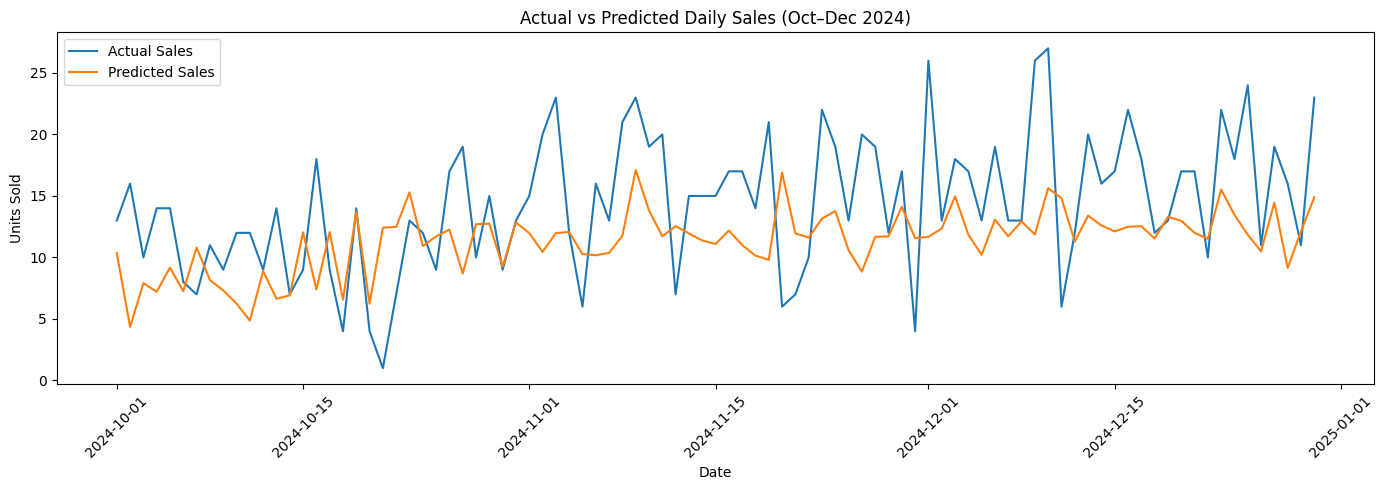

In [ ]:
# Visualize actual versus predicted sales across the chronological test period.
import matplotlib.pyplot as plt
import pandas as pd

# Prepare actual and predicted sales for the test period
results = pd.DataFrame({
    'Date': test_df['Date'].values,
    'Actual_Sales': y_test.values,
    'Predicted_Sales': y_pred
})

results = results.sort_values('Date')

# Plot actual sales against predicted sales
plt.figure(figsize=(14, 5))

plt.plot(
    results['Date'],
    results['Actual_Sales'],
    label='Actual Sales'
)

plt.plot(
    results['Date'],
    results['Predicted_Sales'],
    label='Predicted Sales'
)

plt.title('Actual vs Predicted Daily Sales (Oct–Dec 2024)')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Summarize risk categories and display records requiring urgent replenishment review.
print("Risk classification:")
print(final_recommendations['Lead_Time_Risk'].value_counts())

print("\nUrgent recommendations:")
print(
    final_recommendations[
        final_recommendations['Recommended_Action']
        == 'Urgent: Review replenishment'
    ][[
        'SKU_ID',
        'Warehouse_ID',
        'Inventory_Level',
        'Lead_Time_Demand',
        'Projected_Inventory_At_Delivery',
        'Lead_Time_Risk'
    ]]
)

Risk classification:
Lead_Time_Risk
Inventory May Last         120
Potential Stockout Risk      1
Name: count, dtype: int64

Urgent recommendations:
   SKU_ID Warehouse_ID  Inventory_Level  Lead_Time_Demand  \
17  SKU_2         WH_1              271            271.57   

    Projected_Inventory_At_Delivery           Lead_Time_Risk  
17                            -0.57  Potential Stockout Risk  
